# 02 — Análisis exploratorio descriptivo (EDA)

Este notebook describe las variables, sus escalas y su relación exploratoria con churn. Los gráficos muestran asociaciones, no causalidad. Las agrupaciones por quintiles se usan solo para interpretación visual.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

RAIZ = Path.cwd().resolve()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
PROCESSED = RAIZ / 'data' / 'processed'

train = pd.read_csv(PROCESSED / 'train_preparado.csv', parse_dates=['fecha_nacimiento', 'fecha_inicio_contrato'])
test = pd.read_csv(PROCESSED / 'test_preparado.csv', parse_dates=['fecha_nacimiento', 'fecha_inicio_contrato'])
sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams['figure.dpi'] = 110

## 1. Inventario de variables

La clasificación se basa en el significado de cada variable, no solo en su tipo almacenado: `facturacion` es un monto, `mora` y `minutos` son acumulados, y las variables 0/1 o con pocos niveles son categóricas.

In [3]:
roles = {
    'id': 'identificador (no predictor)', 'fecha_nacimiento': 'fecha', 'fecha_inicio_contrato': 'fecha',
    'tipo_cliente': 'categórica nominal', 'factura_online': 'categórica binaria', 'plan_datos': 'categórica binaria',
    'antiguedad_equipo': 'numérica: meses', 'facturacion': 'numérica: monto acumulado',
    'mora': 'numérica: días acumulados', 'minutos': 'numérica: consumo acumulado',
    'edad_anios': 'numérica derivada', 'antiguedad_contrato_meses': 'numérica derivada',
    'resultado': 'objetivo binario'
}
inventario = pd.DataFrame({
    'rol': pd.Series(roles),
    'tipo': train.dtypes.astype(str),
    'valores_unicos': train.nunique(dropna=False),
    'faltantes': train.isna().sum(),
    'minimo': train.select_dtypes('number').min(),
    'maximo': train.select_dtypes('number').max(),
}).reindex(train.columns)
display(inventario)

,rol,tipo,valores_unicos,faltantes,minimo,maximo
id,identificador (no predictor),int64,8243,0,5.000000,18310.000000
fecha_nacimiento,fecha,datetime64[us],4702,0,NaN,NaN
tipo_cliente,categórica nominal,int64,3,0,1.000000,3.000000
factura_online,categórica binaria,int64,2,0,0.000000,1.000000
antiguedad_equipo,numérica: meses,int64,48,0,1.000000,48.000000
plan_datos,categórica binaria,int64,2,0,0.000000,1.000000
facturacion,numérica: monto acumulado,int64,8151,0,-112588.000000,626111.000000
mora,numérica: días acumulados,int64,106,0,0.000000,118.000000
fecha_inicio_contrato,fecha,datetime64[us],1538,0,NaN,NaN
minutos,numérica: consumo acumulado,int64,2215,0,100.000000,14103.000000


## 2. Variable objetivo y variables categóricas

La primera gráfica muestra el desbalance de la clase objetivo. Para cada variable categórica se muestran distribución de clientes y tasa observada de churn.

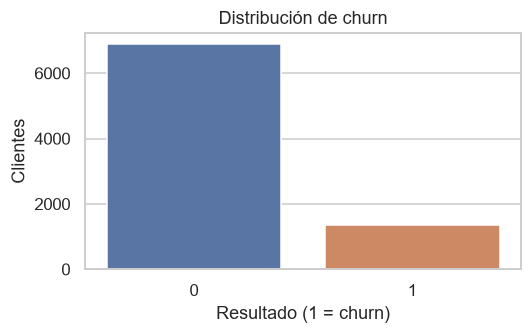

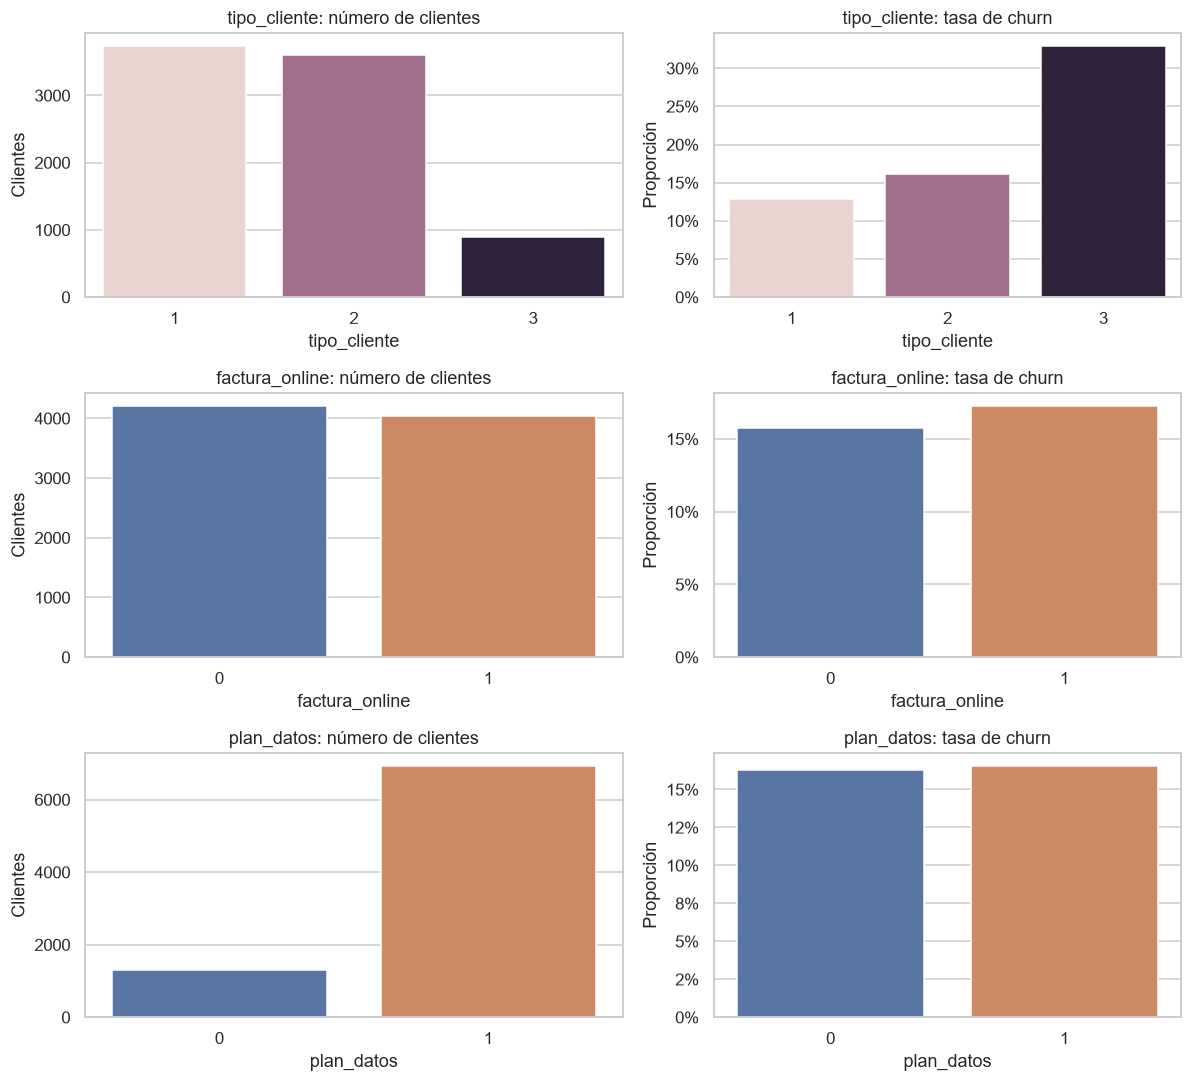

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.2))
orden = sorted(train.resultado.unique())
sns.countplot(data=train, x='resultado', order=orden, hue='resultado', legend=False, ax=ax)
ax.set(title='Distribución de churn', xlabel='Resultado (1 = churn)', ylabel='Clientes')
plt.tight_layout(); plt.show()

categoricas = ['tipo_cliente', 'factura_online', 'plan_datos']
fig, axes = plt.subplots(len(categoricas), 2, figsize=(11, 10), gridspec_kw={'width_ratios': [1.15, 1]})
for fila, col in enumerate(categoricas):
    orden = sorted(train[col].dropna().unique())
    sns.countplot(data=train, x=col, order=orden, hue=col, legend=False, ax=axes[fila, 0])
    tasa = train.groupby(col, observed=False).resultado.agg(['mean', 'size']).reset_index()
    sns.barplot(data=tasa, x=col, y='mean', order=orden, hue=col, legend=False, ax=axes[fila, 1])
    axes[fila, 0].set(title=f'{col}: número de clientes', ylabel='Clientes')
    axes[fila, 1].set(title=f'{col}: tasa de churn', ylabel='Proporción')
    axes[fila, 1].yaxis.set_major_formatter('{x:.0%}')
plt.tight_layout(); plt.show()

## 3. Distribuciones numéricas

Histogramas separados por resultado permiten comparar forma y concentración. Los montos y acumulados pueden estar sesgados: esa evidencia guiará transformaciones posteriores, no se cambia nada todavía.

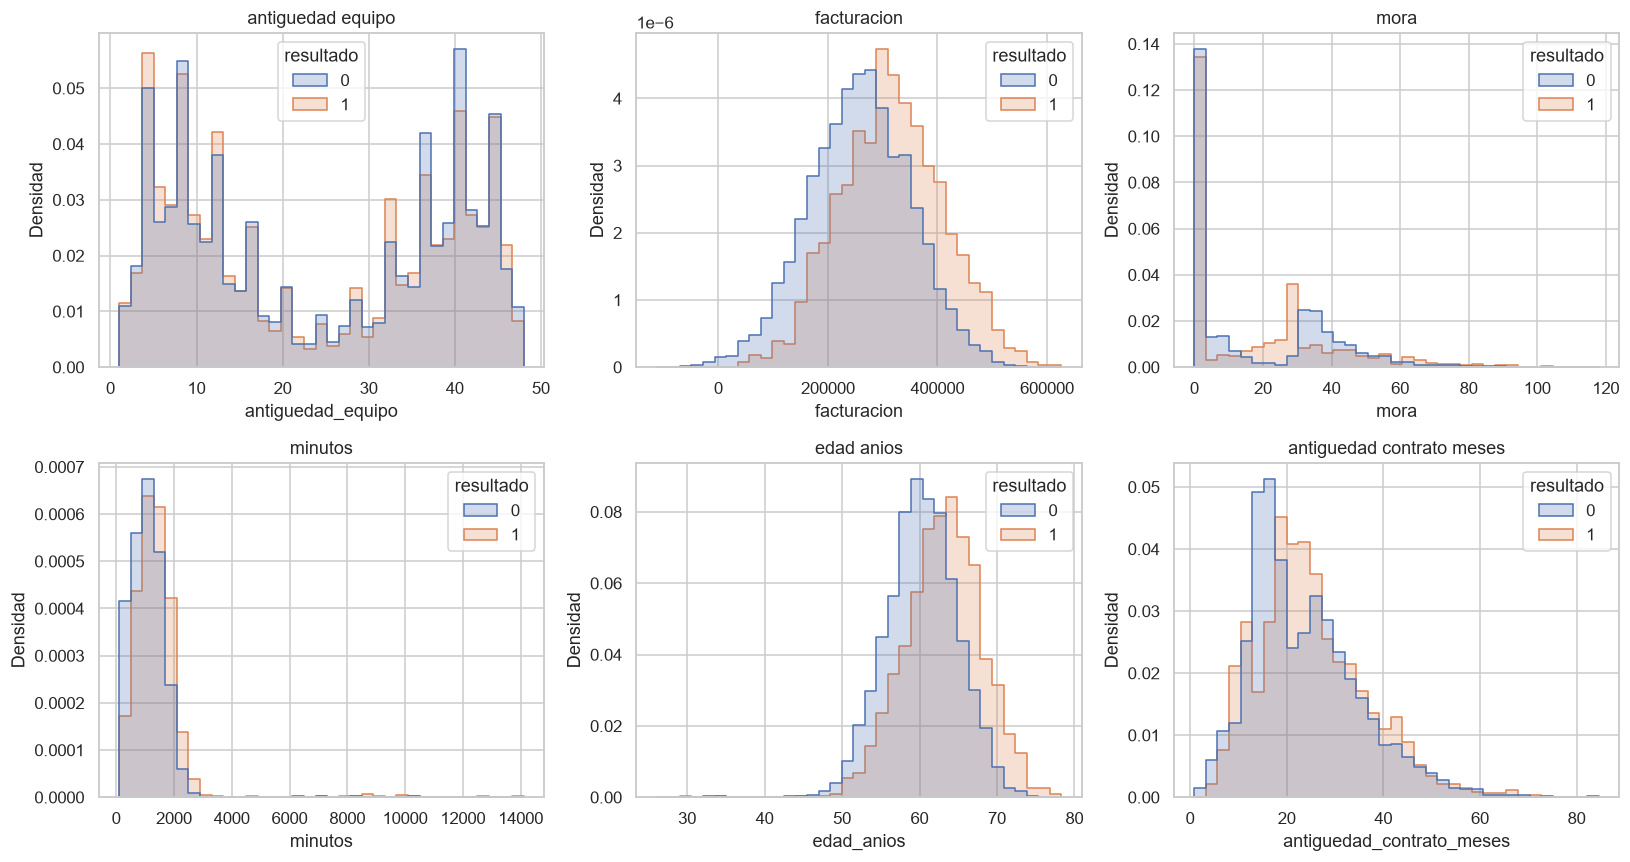

,count,mean,std,min,1%,25%,50%,75%,99%,max
antiguedad_equipo,8243.0,24.27,15.15,1.00,2.00,9.00,24.00,39.00,47.00,48.00
facturacion,8243.0,267765.69,95596.02,-112588.00,41725.38,203363.00,268063.00,333272.50,490251.34,626111.00
mora,8243.0,18.13,21.03,0.00,0.00,0.00,6.00,35.00,77.00,118.00
minutos,8243.0,1183.82,932.84,100.00,137.42,708.00,1103.00,1498.00,3518.56,14103.00
edad_anios,8243.0,60.73,4.89,26.07,49.51,57.67,60.77,63.96,71.53,78.31
antiguedad_contrato_meses,8242.0,23.97,11.38,0.89,4.91,15.44,21.95,30.59,56.58,84.63


In [5]:
numericas = ['antiguedad_equipo', 'facturacion', 'mora', 'minutos', 'edad_anios', 'antiguedad_contrato_meses']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numericas):
    sns.histplot(data=train, x=col, hue='resultado', bins=35, stat='density', common_norm=False, element='step', ax=ax)
    ax.set(title=col.replace('_', ' '), ylabel='Densidad')
plt.tight_layout(); plt.show()

display(train[numericas].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(2))

## 4. Valores extremos y escalas

Las cajas de bigotes revelan dispersión y posibles valores extremos por clase. Esto es especialmente relevante para KNN, que requiere escalamiento y puede ser sensible a extremos.

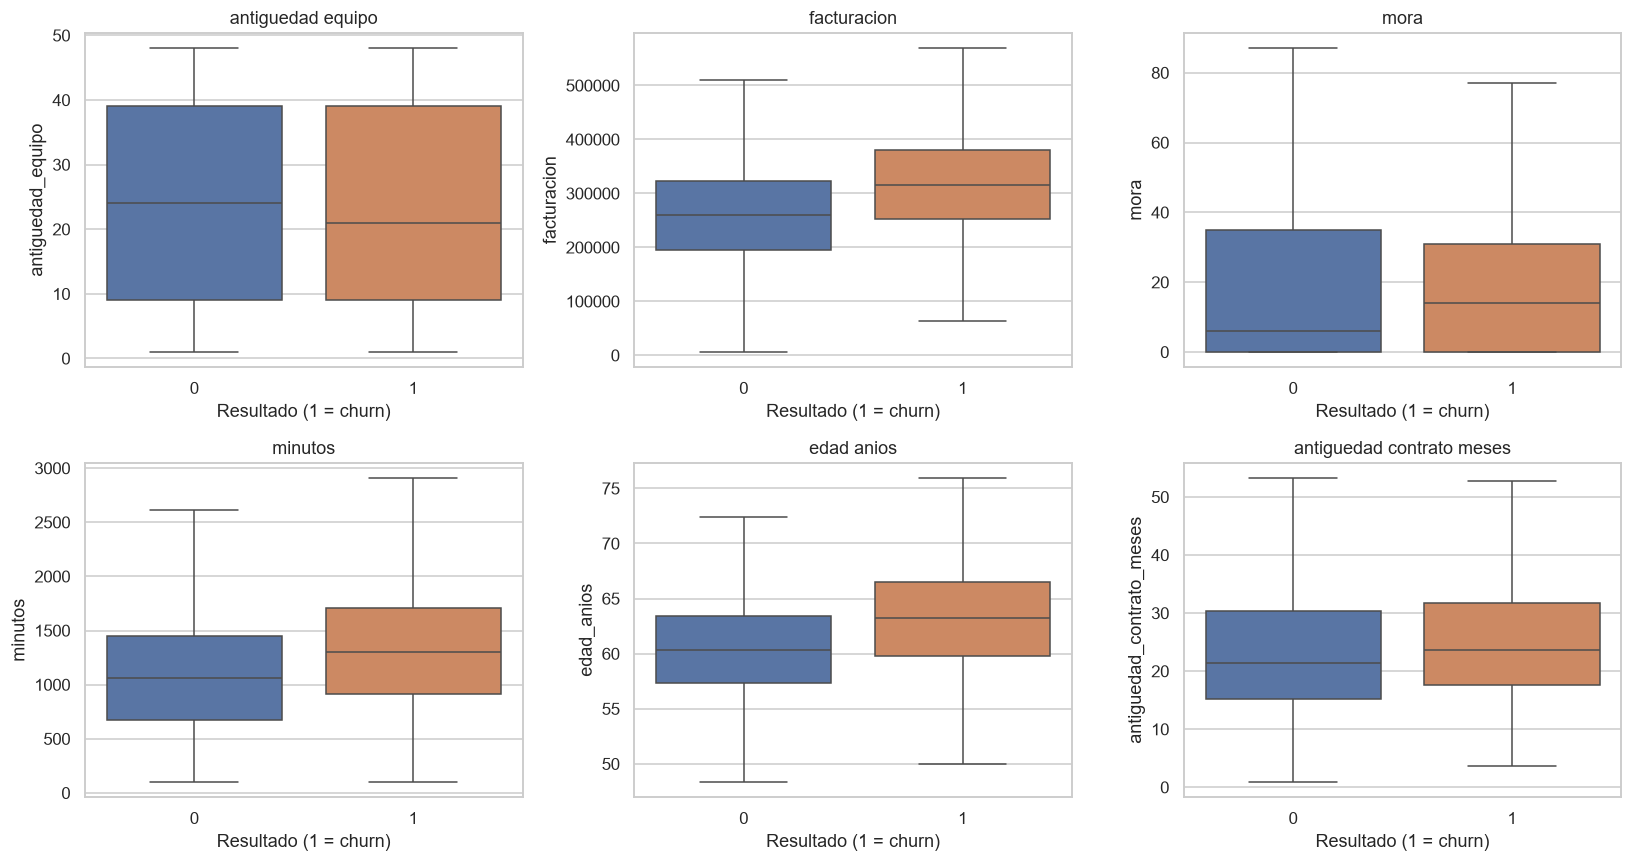

,asimetria
minutos,6.01
mora,0.91
antiguedad_contrato_meses,0.90
edad_anios,-0.41
facturacion,-0.02
antiguedad_equipo,0.02


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numericas):
    sns.boxplot(data=train, x='resultado', y=col, hue='resultado', legend=False, ax=ax, showfliers=False)
    ax.set(title=col.replace('_', ' '), xlabel='Resultado (1 = churn)')
plt.tight_layout(); plt.show()

asimetria = train[numericas].skew().rename('asimetria').to_frame().sort_values('asimetria', key=np.abs, ascending=False)
display(asimetria.round(2))

## 5. Relación exploratoria con churn

Los quintiles crean grupos de tamaño parecido a partir de los valores de train. Sirven para examinar si la tasa de churn cambia de manera aproximadamente monotónica; no reemplazan las variables continuas en el modelo.

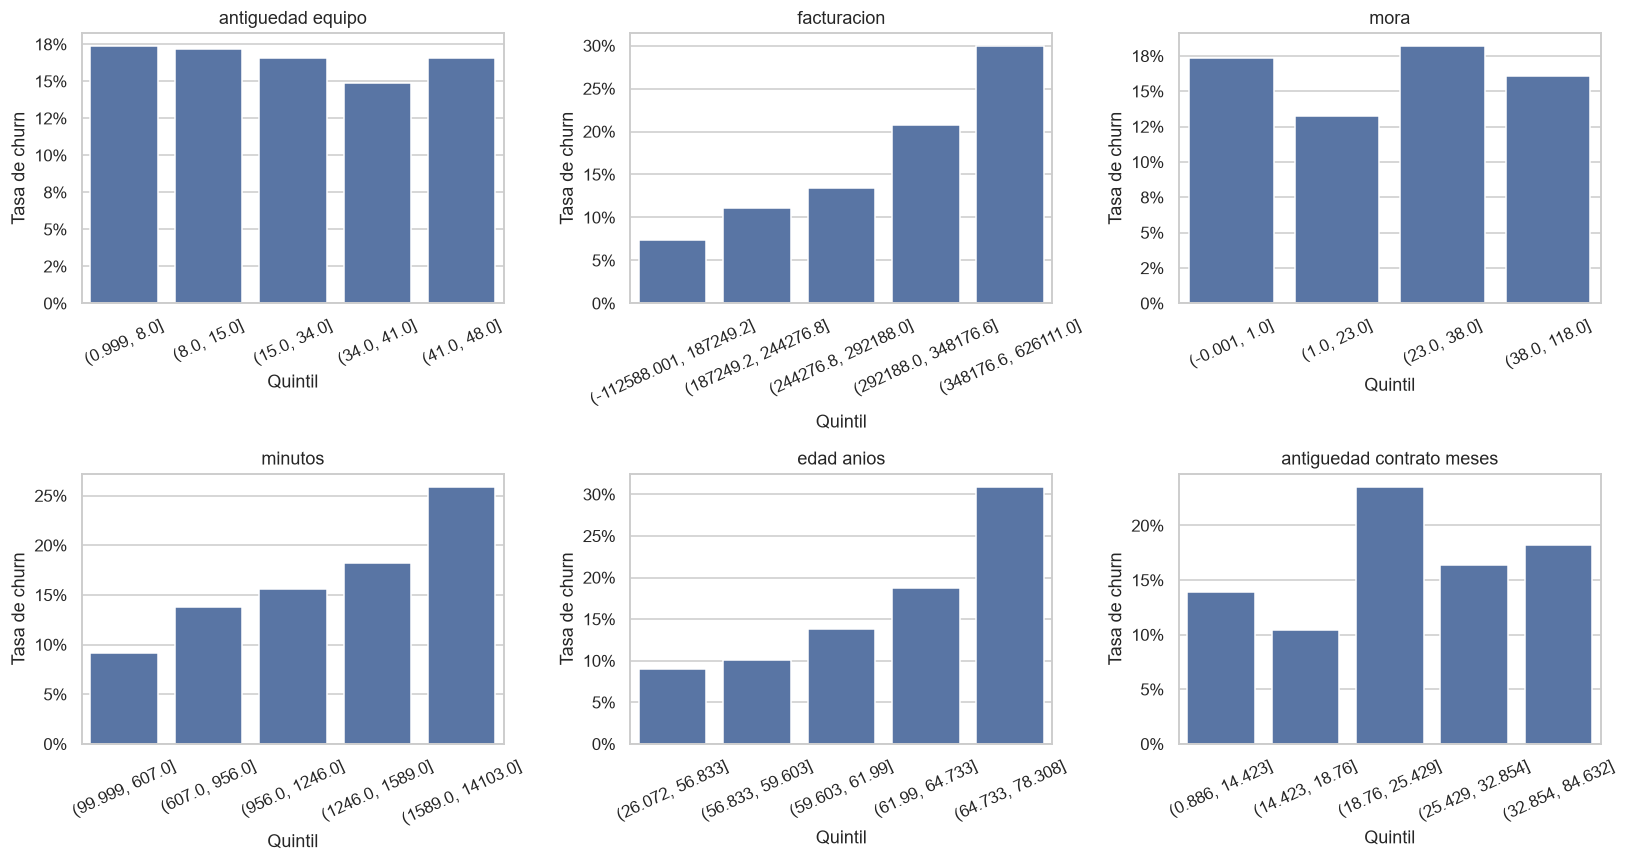

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numericas):
    datos = train[[col, 'resultado']].dropna().copy()
    datos['grupo'] = pd.qcut(datos[col], q=5, duplicates='drop')
    tasa = datos.groupby('grupo', observed=False).resultado.agg(['mean', 'size']).reset_index()
    sns.barplot(data=tasa, x='grupo', y='mean', color=sns.color_palette()[0], ax=ax)
    ax.set(title=col.replace('_', ' '), xlabel='Quintil', ylabel='Tasa de churn')
    ax.tick_params(axis='x', rotation=25)
    ax.yaxis.set_major_formatter('{x:.0%}')
plt.tight_layout(); plt.show()

## 6. Correlación y comparación train/test

La matriz cuantifica relaciones lineales entre variables numéricas. La comparación de distribuciones verifica si test se parece a train; diferencias visibles deben considerarse al evaluar la generalización.

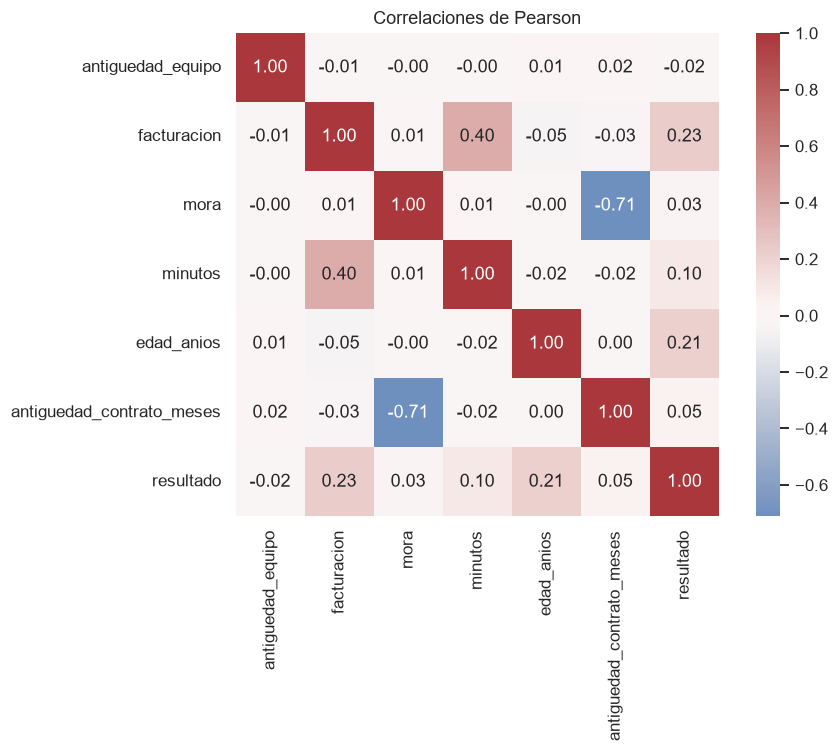

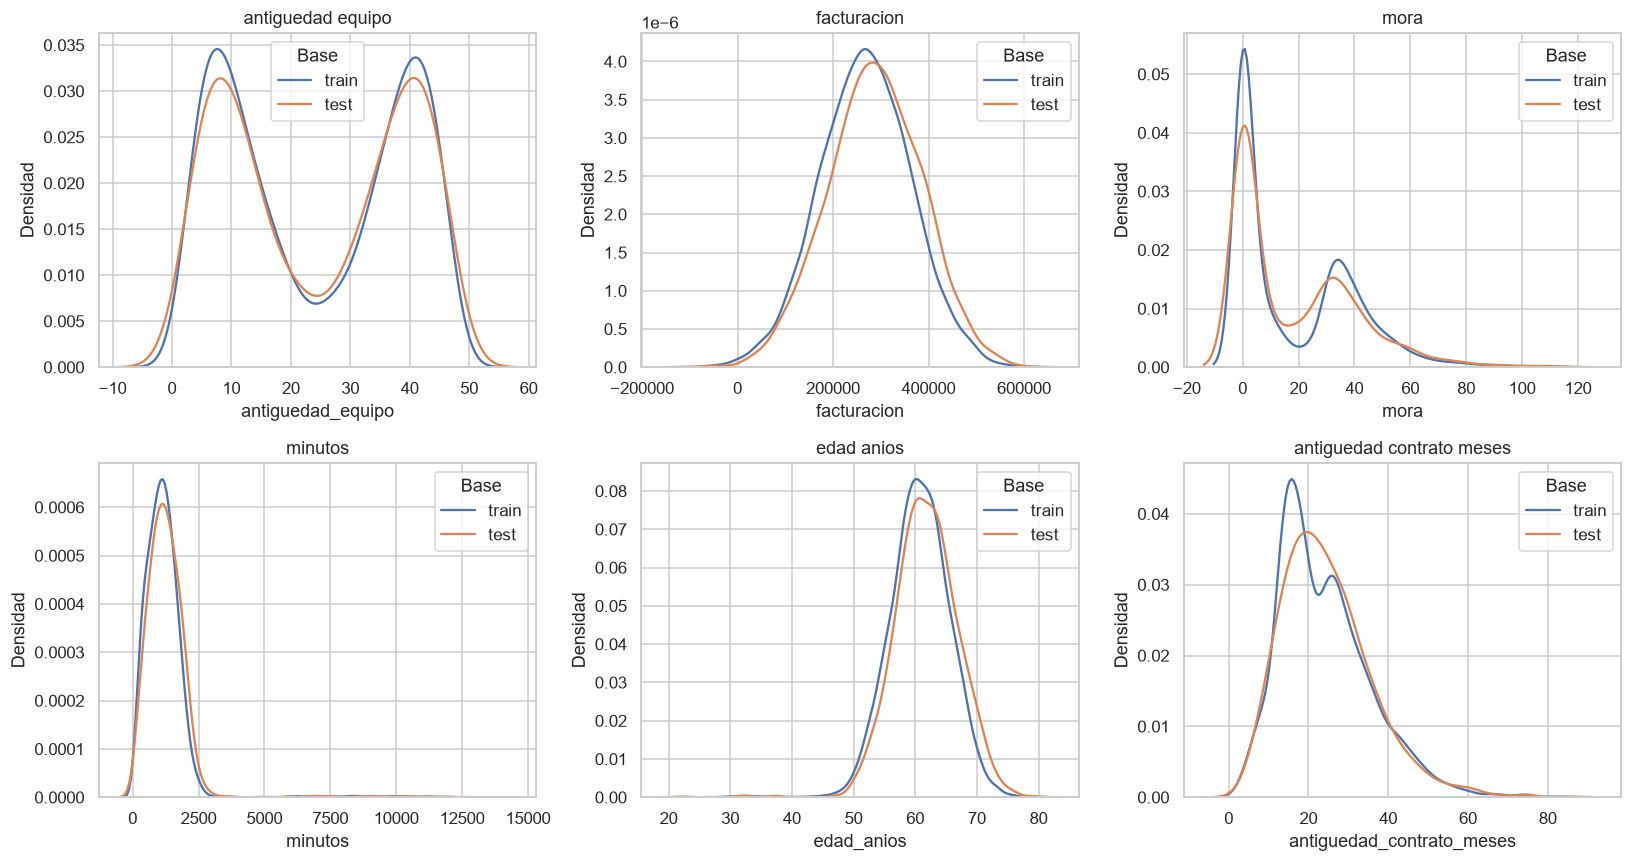

In [8]:
corr_cols = numericas + ['resultado']
plt.figure(figsize=(9, 7))
sns.heatmap(train[corr_cols].corr(), cmap='vlag', center=0, annot=True, fmt='.2f', square=True)
plt.title('Correlaciones de Pearson')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numericas):
    sns.kdeplot(data=train, x=col, label='train', ax=ax, warn_singular=False)
    sns.kdeplot(data=test, x=col, label='test', ax=ax, warn_singular=False)
    ax.set(title=col.replace('_', ' '), ylabel='Densidad')
    ax.legend(title='Base')
plt.tight_layout(); plt.show()

## Lectura para el siguiente paso

Con estos hallazgos se decidirán imputación, codificación, escalamiento y posibles transformaciones. Las decisiones se aplicarán dentro de un `Pipeline` ajustado solo con entrenamiento, para evitar fuga de información.